# Assignment 3 - CNN (MNIST)
**Offline version** - runs without internet.
Needs `mnist.npz` in the same folder (see `00_download_once.ipynb`).

x_train: (60000, 28, 28, 1) x_test: (10000, 28, 28, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │          16,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 - 19s - 44ms/step - accuracy: 0.8881 - loss: 0.3722 - val_accuracy: 0.9772 - val_loss: 0.0832
Epoch 2/10
422/422 - 13s - 32ms/step - accuracy: 0.9657 - loss: 0.1124 - val_accuracy: 0.9853 - val_loss: 0.0546
Epoch 3/10
422/422 - 14s - 32ms/step - accuracy: 0.9739 - loss: 0.0846 - val_accuracy: 0.9862 - val_loss: 0.0473
Epoch 4/10
422/422 - 15s - 35ms/step - accuracy: 0.9784 - loss: 0.0693 - val_accuracy: 0.9892 - val_loss: 0.0407
Epoch 5/10
422/422 - 14s - 34ms/step - accuracy: 0.9804 - loss: 0.0638 - val_accuracy: 0.9890 - val_loss: 0.0381
Epoch 6/10
422/422 - 15s - 35ms/step - accuracy: 0.9822 - loss: 0.0552 - val_accuracy: 0.9893 - val_loss: 0.0359
Epoch 7/10
422/422 - 14s - 33ms/step - accuracy: 0.9840 - loss: 0.0501 - val_accuracy: 0.9898 - val_loss: 0.0340
Epoch 8/10
422/422 - 14s - 33ms/step - accuracy: 0.9849 - loss: 0.0482 - val_accuracy: 0.9902 - val_loss: 0.0333
Epoch 9/10
422/422 - 14s - 33ms/step - accuracy: 0.9867 - loss: 0.0419 - val_accuracy: 0.9908 - 

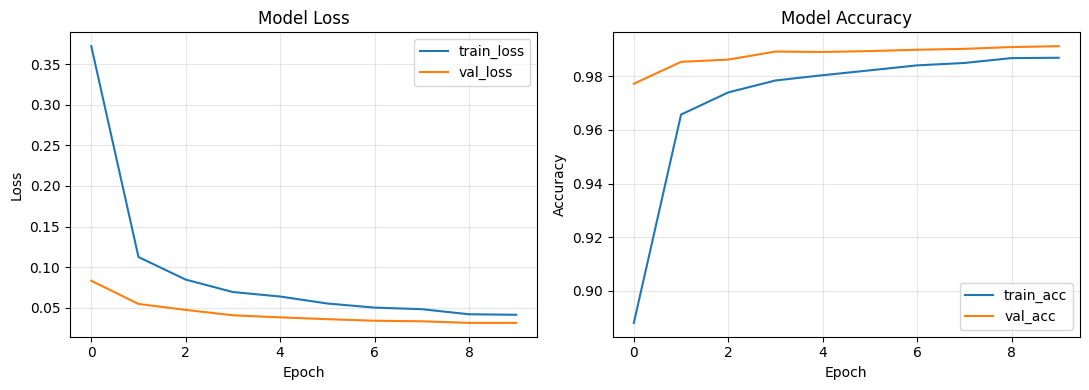

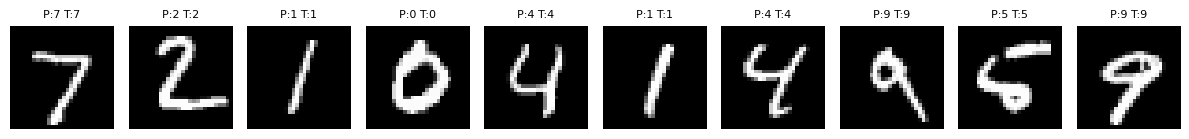


Predicted: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
Actual   : [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]


In [1]:
# Assignment 3 - Image Classification with a CNN (MNIST)

import numpy as np

# ---- OFFLINE MNIST LOADER (no internet needed) --------------------------------
# Reads mnist.npz from the notebook folder (or from ~/.keras/datasets).
# Get the file once from: https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz
import os
def load_mnist(path="mnist.npz"):
    for p in (path, os.path.expanduser("~/.keras/datasets/mnist.npz")):
        if os.path.exists(p):
            with np.load(p, allow_pickle=True) as f:
                return (f["x_train"], f["y_train"]), (f["x_test"], f["y_test"])
    raise FileNotFoundError("mnist.npz not found. Put it in the same folder as this notebook "
        "(download link: https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz)")
# -------------------------------------------------------------------------------

import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)


# a. Loading and preprocessing the image data
(x_train, y_train), (x_test, y_test) = load_mnist()

# Normalize pixel values between 0 and 1
x_train = x_train.astype("float32")[..., None] / 255.0
x_test = x_test.astype("float32")[..., None] / 255.0

# Convert labels into one-hot encoded format
y_train_c = keras.utils.to_categorical(y_train, 10)
y_test_c = keras.utils.to_categorical(y_test, 10)

print("x_train:", x_train.shape, "x_test:", x_test.shape)


# b. Defining the CNN model architecture
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

# Display model architecture
model.summary()


# c. Compiling and training the model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

H = model.fit(
    x_train,
    y_train_c,
    batch_size=128,
    epochs=10,
    validation_split=0.1,
    verbose=2
)


# d. Evaluating model performance on test data
loss, acc = model.evaluate(x_test, y_test_c, verbose=0)

print(f"\nTest loss: {loss:.4f}")
print(f"Test accuracy: {acc:.4f}")


# e. Plotting training and validation loss and accuracy
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Model Loss graph
ax[0].plot(H.history["loss"], label="train_loss")
ax[0].plot(H.history["val_loss"], label="val_loss")
ax[0].set_title("Model Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Model Accuracy graph
ax[1].plot(H.history["accuracy"], label="train_acc")
ax[1].plot(H.history["val_accuracy"], label="val_acc")
ax[1].set_title("Model Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("a3_curves.png", dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)


# f. Predicting the first 10 test images
pred = model.predict(x_test[:10], verbose=0).argmax(axis=1)

# Display sample predictions
fig, ax = plt.subplots(1, 10, figsize=(12, 1.8))

for i in range(10):
    ax[i].imshow(x_test[i, :, :, 0], cmap="gray")
    ax[i].axis("off")
    ax[i].set_title(
        f"P:{pred[i]} T:{y_test[i]}",
        fontsize=8
    )

plt.tight_layout()
plt.savefig("a3_predictions.png", dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)


# g. Printing predicted and actual labels
print("\nPredicted:", pred.tolist())
print("Actual   :", y_test[:10].tolist())